In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
INTERIM = PROJECT_ROOT / "data" / "interim"

DATA_FILE = INTERIM / "cafe_cleaned.csv"

cafe_df = pd.read_csv(DATA_FILE)

print("Shape:", cafe_df.shape)
cafe_df.head()

Shape: (552, 20)


,name,url,location,din_rev,del_rev,category,cuisine_offered,cost_for_two,is_vegeterian,is_bar_available,home_delivery,offers_dining,avg_din_rate,avg_del_rate,is_explicit_cafe,has_cafe_type_cuisine,has_cafe_name_signal,is_cafescope_cafe,dining_review_count,delivery_review_count
0,11MG,https://www.zomato.com/jaipur/11mg-mansarovar,Mansarovar,135 Dining Reviews,837 Delivery Reviews,CAFE,Cafe,400.0,True,False,True,True,3.8,3.9,True,True,False,True,135.0,837.0
1,365 Cafe,https://www.zomato.com/jaipur/365-cafe-malviya...,Malviya Nagar,Not enough Dining Reviews,Does not offer Delivery,Quick Bites,"Fast Food, Beverages",400.0,True,False,False,True,NaN,NaN,False,True,True,True,NaN,NaN
2,4 Friends Cafe,https://www.zomato.com/jaipur/4-friends-cafe-t...,Durgapura,Not enough Dining Reviews,Not enough Delivery Reviews,Quick Bites,Fast Food,150.0,False,False,True,True,NaN,NaN,False,False,True,True,NaN,NaN
3,8 Fumes,https://www.zomato.com/jaipur/8-fumes-mansarovar,Mansarovar,8 Dining Reviews,Does not offer Delivery,CAFE,"Cafe, Fast Food",400.0,True,False,False,True,2.8,NaN,True,True,False,True,8.0,NaN
4,999.pt Cafe - Restaurant,https://www.zomato.com/jaipur/999-pt-cafe-rest...,Pratap Nagar,111 Dining Reviews,"2,537 Delivery Reviews",Quick Bites,"North Indian, Fast Food",300.0,False,False,True,True,2.7,2.8,False,False,True,True,111.0,2537.0


In [2]:
cafe_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 552 entries, 0 to 551
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   name                   552 non-null    str    
 1   url                    552 non-null    str    
 2   location               552 non-null    str    
 3   din_rev                552 non-null    str    
 4   del_rev                552 non-null    str    
 5   category               552 non-null    str    
 6   cuisine_offered        552 non-null    str    
 7   cost_for_two           527 non-null    float64
 8   is_vegeterian          552 non-null    bool   
 9   is_bar_available       552 non-null    bool   
 10  home_delivery          552 non-null    bool   
 11  offers_dining          552 non-null    bool   
 12  avg_din_rate           409 non-null    float64
 13  avg_del_rate           242 non-null    float64
 14  is_explicit_cafe       552 non-null    bool   
 15  has_cafe_type_cui

In [3]:
cafe_df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,552,520,Cafe Coffee Day,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
url,552,552,https://www.zomato.com/jaipur/11mg-mansarovar,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,552,43,Malviya Nagar,67,NaN,NaN,NaN,NaN,NaN,NaN,NaN
din_rev,552,194,Not enough Dining Reviews,91,NaN,NaN,NaN,NaN,NaN,NaN,NaN
del_rev,552,208,Not enough Delivery Reviews,160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,552,30,Quick Bites,198,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cuisine_offered,552,268,Cafe,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cost_for_two,527.0,NaN,NaN,NaN,415.654649,179.131561,100.0,300.0,400.0,500.0,900.0
is_vegeterian,552,2,True,291,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_bar_available,552,2,False,542,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
location_counts = (
    cafe_df["location"]
    .value_counts()
    .reset_index()

)

location_counts.columns = ["location", "cafe_count"]

location_counts.head(20)

,location,cafe_count
0,Malviya Nagar,67
1,Mansarovar,66
2,C Scheme,46
3,Vaishali Nagar,39
4,Pratap Nagar,29
5,Jagatpura,26
6,Raja Park,25
7,Jhotwara,22
8,Lal Kothi,19
9,Durgapura,18


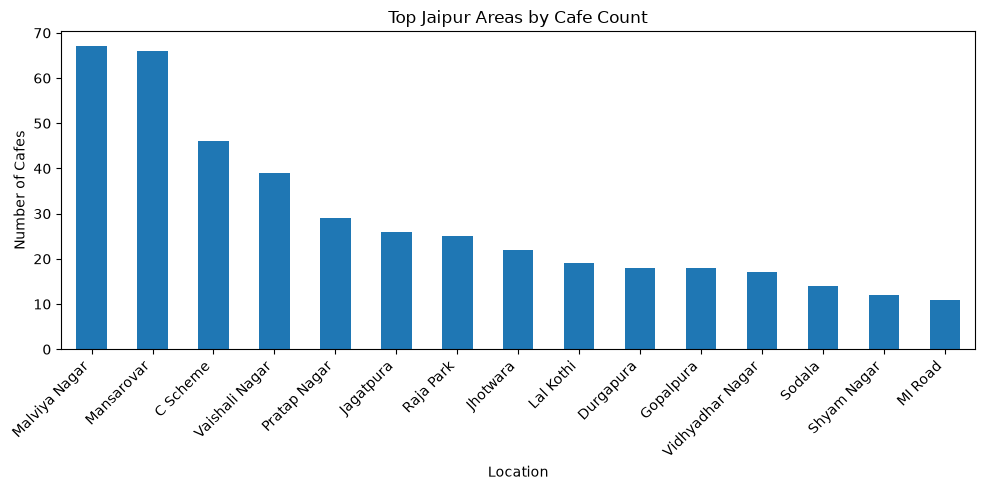

In [5]:
location_counts.head(15).plot(
    x="location",
    y="cafe_count",
    kind="bar",
    figsize=(10, 5),
    legend=False
)

plt.title("Top Jaipur Areas by Cafe Count")
plt.xlabel("Location")
plt.ylabel("Number of Cafes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [6]:
cafe_df["cost_for_two"].describe()

count    527.000000
mean     415.654649
std      179.131561
min      100.000000
25%      300.000000
50%      400.000000
75%      500.000000
max      900.000000
Name: cost_for_two, dtype: float64

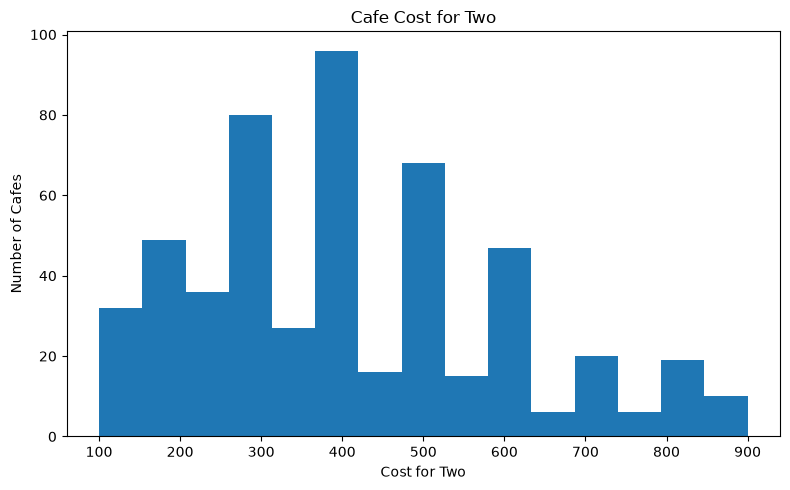

In [7]:
cafe_df["cost_for_two"].plot(
    kind="hist",
    bins=15,
    figsize=(8, 5)
)

plt.title("Cafe Cost for Two")
plt.xlabel("Cost for Two")
plt.ylabel("Number of Cafes")
plt.tight_layout()
plt.show()

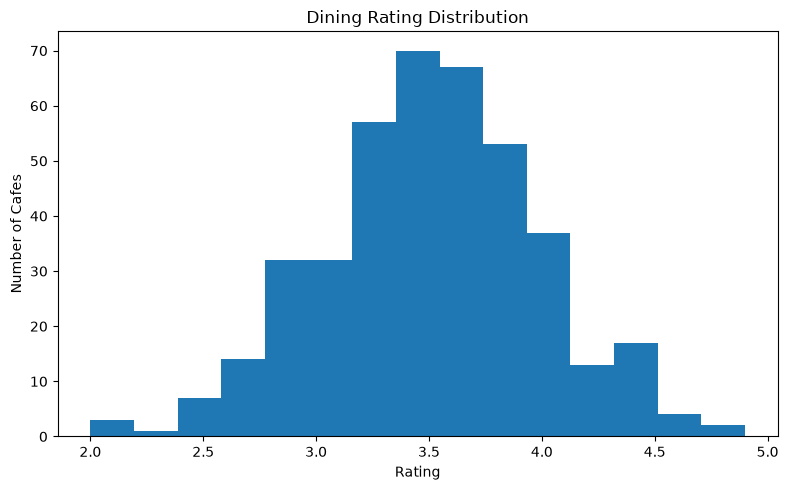

In [8]:
cafe_df["avg_din_rate"].plot(
    kind="hist",
    bins=15,
    figsize=(8, 5)
)

plt.title("Dining Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Cafes")
plt.tight_layout()
plt.show()

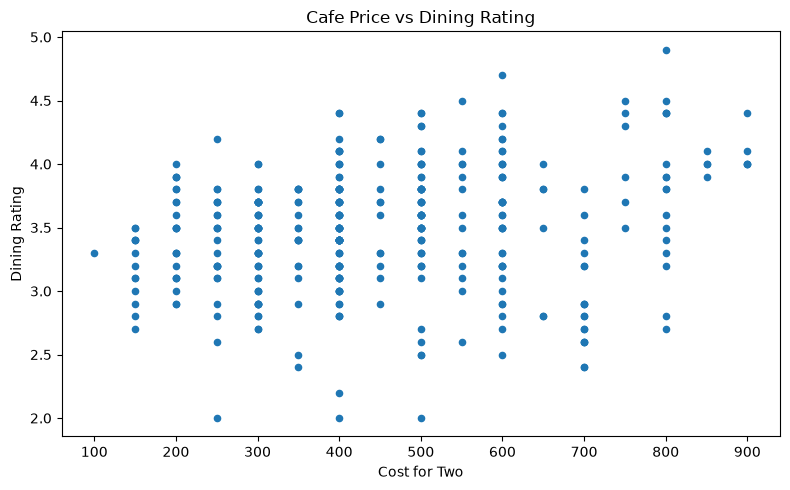

In [9]:
cafe_df.plot(
    x="cost_for_two",
    y="avg_din_rate",
    kind="scatter",
    figsize=(8, 5)
)

plt.title("Cafe Price vs Dining Rating")
plt.xlabel("Cost for Two")
plt.ylabel("Dining Rating")
plt.tight_layout()
plt.show()

In [10]:
cafe_df["dining_review_count"].describe()

count    420.000000
mean     103.954762
std      171.420571
min        1.000000
25%       10.000000
50%       37.000000
75%      113.250000
max      984.000000
Name: dining_review_count, dtype: float64

In [11]:
top_popular = (
    cafe_df[
        ["name", "location", "avg_din_rate", "dining_review_count"]
    ]
    .sort_values(
        "dining_review_count",
        ascending=False
    )
    .head(20)
)

top_popular

,name,location,avg_din_rate,dining_review_count
505,The Rustic Spot Cafe,Mansarovar,4.3,984.0
440,Tea Connect Cafe,Mansarovar,4.3,971.0
284,Ki & Ka Kafe Restaurant,Chitrakoot,4.0,892.0
171,Curious Life Coffee Roasters- Sarojini Marg,C Scheme,4.7,879.0
447,TeaQuila - A Fashion Cafe,Malviya Nagar,3.6,861.0
285,La Palma Cafe and Lounge Bar,C Scheme,4.3,829.0
371,Quyu's Cafe,Vaishali Nagar,4.4,757.0
338,Nibs Cafe and Chocolataria,Bais Godam,4.4,744.0
436,Tapri Pratham,Lal Kothi,4.4,707.0
502,The PentHouse,Malviya Nagar,3.8,698.0


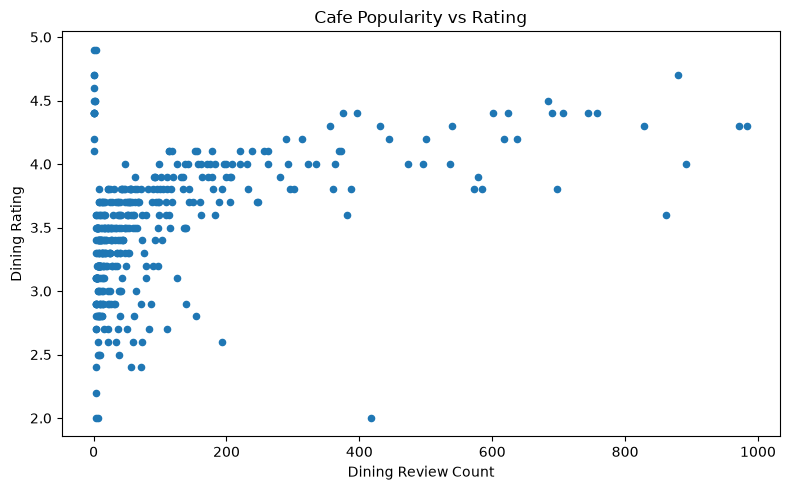

In [12]:
cafe_df.plot(
    x="dining_review_count",
    y="avg_din_rate",
    kind="scatter",
    figsize=(8, 5)
)

plt.title("Cafe Popularity vs Rating")
plt.xlabel("Dining Review Count")
plt.ylabel("Dining Rating")
plt.tight_layout()
plt.show()

In [13]:
cuisine_counts = (
    cafe_df["cuisine_offered"]
    .fillna("Unknown")
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
)

cuisine_counts.head(20)

cuisine_offered
Fast Food       345
Cafe            222
Beverages       199
Chinese         173
North Indian    166
Italian          75
South Indian     54
Continental      51
Desserts         40
Pizza            32
Bakery           29
Street Food      26
Sandwich         22
Mexican          12
Burger            9
Juices            9
Healthy Food      8
Ice Cream         8
Coffee            8
Tea               7
Name: count, dtype: int64

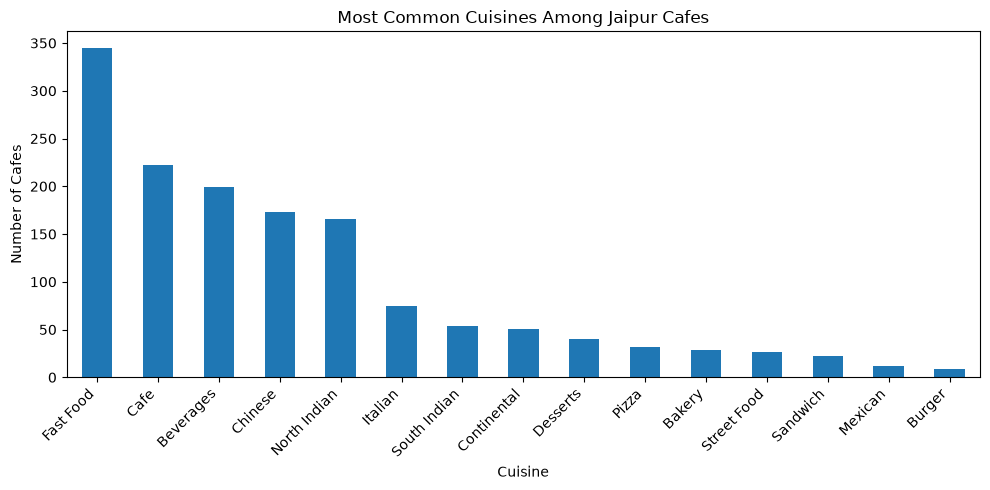

In [14]:
cuisine_counts.head(15).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Most Common Cuisines Among Jaipur Cafes")
plt.xlabel("Cuisine")
plt.ylabel("Number of Cafes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [15]:
feature_summary = pd.DataFrame({
    'Vegetarian': cafe_df['is_vegeterian'].mean() * 100,
    'Bar Available': cafe_df['is_bar_available'].mean() * 100,
    'Home Delivery': cafe_df['home_delivery'].mean() * 100,
    'Dining Offered': cafe_df['offers_dining'].mean() * 100
}, index=['Percentage'])

feature_summary.round(2)


,Vegetarian,Bar Available,Home Delivery,Dining Offered
Percentage,52.72,1.81,74.28,92.57


In [16]:
numeric_cols = [
    "cost_for_two",
    "avg_din_rate",
    "avg_del_rate",
    "dining_review_count",
    "delivery_review_count"
]

cafe_df[numeric_cols].corr().round(2)

,cost_for_two,avg_din_rate,avg_del_rate,dining_review_count,delivery_review_count
cost_for_two,1.00,0.22,0.02,0.34,0.18
avg_din_rate,0.22,1.00,0.34,0.48,0.34
avg_del_rate,0.02,0.34,1.00,0.05,0.05
dining_review_count,0.34,0.48,0.05,1.00,0.38
delivery_review_count,0.18,0.34,0.05,0.38,1.00


In [17]:
analysis_cols = [
    "cost_for_two",
    "avg_din_rate",
    "dining_review_count",
    "delivery_review_count"
]

cafe_df[analysis_cols].corr().round(2)

,cost_for_two,avg_din_rate,dining_review_count,delivery_review_count
cost_for_two,1.00,0.22,0.34,0.18
avg_din_rate,0.22,1.00,0.48,0.34
dining_review_count,0.34,0.48,1.00,0.38
delivery_review_count,0.18,0.34,0.38,1.00


In [18]:
bins = [0, 300, 500, 700, 1000]
labels = ["Budget", "Mid-range", "Upper-mid", "Premium"]

cafe_df["price_segment"] = pd.cut(
    cafe_df["cost_for_two"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

cafe_df["price_segment"].value_counts().sort_index()

price_segment
Budget       197
Mid-range    207
Upper-mid     88
Premium       35
Name: count, dtype: int64

In [19]:
cafe_df.groupby("price_segment", observed=True)[
    ["avg_din_rate", "dining_review_count"]
].mean().round(2)

,avg_din_rate,dining_review_count
price_segment,,
Budget,3.35,39.82
Mid-range,3.50,93.86
Upper-mid,3.43,137.76
Premium,3.92,254.55


In [20]:
# Define popularity using the median review count

review_median = cafe_df["dining_review_count"].median()

print("Median dining reviews:", review_median)


Median dining reviews: 37.0


In [21]:
cafe_df["popularity_segment"] = np.where(
    cafe_df["dining_review_count"] >= review_median,
    "High Popularity",
    "Low Popularity"
)

In [22]:
rating_median = cafe_df["avg_din_rate"].median()

print("Median dining rating:", rating_median)

Median dining rating: 3.5


In [23]:
cafe_df["rating_segment"] = np.where(
    cafe_df["avg_din_rate"] >= rating_median,
    "High Rating",
    "Low Rating"
)

In [24]:
cafe_df["market_segment"] = (
    cafe_df["rating_segment"]
    + " + "
    + cafe_df["popularity_segment"]
)

In [25]:
cafe_df["market_segment"].value_counts()

market_segment
Low Rating + Low Popularity      271
High Rating + High Popularity    165
High Rating + Low Popularity      70
Low Rating + High Popularity      46
Name: count, dtype: int64

In [26]:
underrated_candidates = (
    cafe_df[
        (cafe_df["rating_segment"] == "High Rating") &
        (cafe_df["popularity_segment"] == "Low Popularity")
    ]
    [
        [
            "name",
            "location",
            "avg_din_rate",
            "dining_review_count",
            "cost_for_two"
        ]
    ]
    .sort_values(
        ["avg_din_rate", "dining_review_count"],
        ascending=[False, True]
    )
)

underrated_candidates.head(20)


,name,location,avg_din_rate,dining_review_count,cost_for_two
551,Zolocrust,Malviya Nagar,4.9,1.0,NaN
435,Tapri Central,C Scheme,4.9,3.0,800.0
57,CAF� Bae,Bais Godam,4.7,1.0,NaN
139,Chool,C Scheme,4.7,1.0,NaN
350,On The House,C Scheme,4.6,1.0,NaN
339,Nibs Experia,C Scheme,4.5,1.0,750.0
111,Cafe LazyMojo,Malviya Nagar,4.5,2.0,800.0
427,Sultanat,Malviya Nagar,4.5,2.0,NaN
49,Brown Sugar - Restaurant Cafe Bakery,C Scheme,4.4,1.0,600.0
50,"Brown Sugar - Restaurant, Cafe, Bakery",Vaishali Nagar,4.4,1.0,600.0


In [27]:
feature_summary = pd.DataFrame({
    "Vegetarian": cafe_df["is_vegeterian"].mean() * 100,
    "Bar Available": cafe_df["is_bar_available"].mean() * 100,
    "Home Delivery": cafe_df["home_delivery"].mean() * 100,
    "Dining Offered": cafe_df["offers_dining"].mean() * 100
}, index=['Percentage'])

feature_summary.round(2)

,Vegetarian,Bar Available,Home Delivery,Dining Offered
Percentage,52.72,1.81,74.28,92.57


In [28]:
area_summary = (
    cafe_df.groupby("location")
    .agg(
        cafe_count=("name", "count"),
        avg_rating=("avg_din_rate", "mean"),
        avg_cost=("cost_for_two", "mean"),
        avg_reviews=("dining_review_count", "mean")
    )
    .sort_values("cafe_count", ascending=False)
)

area_summary.head(15).round(2)

,cafe_count,avg_rating,avg_cost,avg_reviews
location,,,,
Malviya Nagar,67,3.54,472.31,94.09
Mansarovar,66,3.42,371.97,86.92
C Scheme,46,3.82,540.79,192.72
Vaishali Nagar,39,3.54,466.22,96.81
Pratap Nagar,29,3.38,305.17,43.33
Jagatpura,26,3.19,326.92,31.81
Raja Park,25,3.53,386.00,111.44
Jhotwara,22,3.05,331.82,11.23
Lal Kothi,19,3.66,494.74,223.12


In [29]:
eda_output = INTERIM / "cafe_eda.csv"
cafe_df.to_csv(eda_output, index=False)
print("EDA snapshot saved:", eda_output)

EDA snapshot saved: /Users/priyashekhawat/Desktop/ree/project/cafescope/data/interim/cafe_eda.csv
